# Avance 1. Análisis exploratorio de datos (EDA)
## Vetlife Almacén  segmentación de productos con YOLO

**Equipo:** #Equipo 32
**Fecha de entrega:** 4 de octubre de 2026

**Objetivo:** analizar solo las imágenes que ya tienen etiquetas de segmentación válidas y tratar este export etiquetado como la muestra completa disponible para esta actividad.



### Adaptación del EDA tabular a YOLO

Una fila representa una imagen o una instancia de producto. Cada instancia está descrita por un ID de clase y un polígono de coordenadas x,y normalizadas. Se derivan medidas como dimensiones de imagen, proporción, brillo, número de objetos, cantidad de vértices y área de la caja envolvente.

| Pregunta de la actividad | Adaptación a este conjunto |
|---|---|
| Estructura, estadísticas y faltantes | Dimensiones y apariencia de imágenes etiquetadas; validez de pares y polígonos |
| Variables categóricas y cardinalidad | Clases observadas y frecuencia por clase y partición |
| Sesgo y valores atípicos | Distribuciones de tamaño, brillo, objetos por imagen y área de caja |
| Análisis bi/multivariante | Correlaciones de medidas, geometría por clase y coocurrencia |
| Normalización | Coordenadas ya normalizadas a [0,1]; píxeles RGB escalados a [0,1] para preparar el modelo |
| Tendencias temporales | No hay fecha o sesión confiable; no se infiere tiempo de los nombres IMG_n |

La muestra del EDA está formada por todas las imágenes del export que tengan al menos un polígono YOLO válido. El análisis describe esta muestra etiquetada, no todo el catálogo ni futuras escenas del almacén. Los IDs de clase se conservan porque identifican presentaciones distintas. En este problema, el modelo recibe los píxeles y aprende sus propias representaciones; ancho, brillo y geometría derivados aquí son descriptores de calidad para el EDA, no sustitutos de la imagen. Con 60 instancias no se justifica seleccionar variables manuales ni eliminar información visual; los IDs de clase tampoco se tratan como valores ordinales.

### Hallazgo preliminar del export disponible

La revisión de los archivos actuales encontró **60 imágenes etiquetadas** (42 train, 9 validation y 9 test), con **60 instancias**: una por imagen. El mapa declara 20 clases; en las etiquetas aparecen los IDs 0–4 y 11–14, es decir, 9 clases observadas. Este es el conjunto completo de datos etiquetados disponible para este avance. Las celdas siguientes vuelven a calcular estas cifras directamente desde el ZIP.


## 1. Cargar los datos



In [1]:
from pathlib import Path
import zipfile

ORIGEN = "subir"  # opciones: subir, drive
ZIP_EN_DRIVE = "/content/drive/MyDrive/vetlife-yolo-local-20260929051531.zip"
EXTRACCION = Path("/content/avance1_yolo_dataset")
LOCAL_DATA_DIR = Path.cwd() / "vetlife-yolo-local-20260929051531"
COLAB_DATA_DIR = EXTRACCION / "vetlife-yolo-local-20260929051531"

# Permite ejecutar este mismo notebook desde la carpeta local del proyecto o Colab.
if (LOCAL_DATA_DIR / "data.yaml").is_file():
    DATA_DIR = LOCAL_DATA_DIR
elif (COLAB_DATA_DIR / "data.yaml").is_file():
    DATA_DIR = COLAB_DATA_DIR
else:
    if ORIGEN == "drive":
        from google.colab import drive
        drive.mount("/content/drive")
        zip_path = Path(ZIP_EN_DRIVE)
        if not zip_path.is_file():
            raise FileNotFoundError(f"No encuentro el ZIP: {zip_path}")
    else:
        from google.colab import files
        uploaded = files.upload()
        zip_names = [name for name in uploaded if name.lower().endswith(".zip")]
        if not zip_names:
            raise FileNotFoundError("Carga el ZIP del dataset YOLO.")
        zip_path = Path("/content") / zip_names[0]

    EXTRACCION.mkdir(parents=True, exist_ok=True)
    destino = EXTRACCION.resolve()
    with zipfile.ZipFile(zip_path) as zf:
        for member in zf.infolist():
            target = (EXTRACCION / member.filename).resolve()
            if target != destino and destino not in target.parents:
                raise ValueError(f"Ruta inesperada dentro del ZIP: {member.filename}")
        zf.extractall(EXTRACCION)
    yaml_files = list(EXTRACCION.rglob("data.yaml"))
    if len(yaml_files) != 1:
        raise FileNotFoundError(f"Esperaba un data.yaml y encontré {len(yaml_files)}.")
    DATA_DIR = yaml_files[0].parent

assert (DATA_DIR / "images").is_dir()
assert (DATA_DIR / "labels").is_dir()
print("Dataset YOLO de segmentación cargado desde la carpeta local.")

Dataset YOLO de segmentación cargado desde la carpeta local.


## 2. Librerías y mapa de clases

Las etiquetas YOLO de segmentación contienen el ID de clase seguido por al menos tres pares de coordenadas. Se valida que las coordenadas sean finitas y estén en el rango normalizado [0,1].

In [2]:
import re
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageDraw
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def leer_nombres_yolo(ruta):
    nombres, dentro = [], False
    for linea in Path(ruta).read_text(encoding="utf-8").splitlines():
        limpio = linea.strip()
        if limpio.startswith("names:"):
            dentro = True
            resto = limpio[len("names:"):].strip()
            if resto.startswith("[") and resto.endswith("]"):
                return [x.strip().strip("\"'") for x in resto[1:-1].split(",")]
            continue
        if dentro:
            if re.match(r"^\s*-\s+", linea):
                valor = re.sub(r"^\s*-\s+", "", linea).strip()
                nombres.append(valor.strip("\"'"))
            elif limpio:
                break
    if not nombres:
        raise ValueError("No se encontró la lista names en data.yaml.")
    return nombres

CLASS_NAMES = leer_nombres_yolo(DATA_DIR / "data.yaml")
SPLITS = {"train": "train", "validation": "validation", "test": "test"}
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}
print(f"Clases declaradas en el mapa: {len(CLASS_NAMES)}")
display(pd.DataFrame({"class_id": range(len(CLASS_NAMES)), "clase": CLASS_NAMES}))

Clases declaradas en el mapa: 20


,class_id,clase
0,0,bravecto 1M 2 - 4.5
1,1,bravecto 1M 4.5 - 10
2,2,bravecto 1M 10 - 20
3,3,bravecto 1M 20 - 40
4,4,bravecto 1M triple 1.27-2.5
5,5,bravecto 1M triple 2.5-5.0
6,6,bravecto 1M triple 5.0-10
7,7,bravecto 1M triple 10-20
8,8,bravecto 1M triple 20-40
9,9,bravecto 1M triple 40-60


## 3. Construir la muestra etiquetada y auditar anotaciones

Solo se incluyen en las tablas de análisis imágenes legibles con una o más instancias válidas. Imágenes sin etiqueta, etiquetas vacías, imágenes ilegibles o etiquetas sin polígonos válidos se excluyen y su cantidad se reporta, sin analizar sus imágenes.

In [3]:
image_rows, instance_rows, invalid_rows, excluded_rows = [], [], [], []

for split, folder in SPLITS.items():
    image_dir = DATA_DIR / "images" / folder
    label_dir = DATA_DIR / "labels" / folder
    image_paths = sorted(p for p in image_dir.rglob("*") if p.is_file() and p.suffix.lower() in IMAGE_EXTS)
    label_paths = {p.stem: p for p in label_dir.glob("*.txt")} if label_dir.exists() else {}

    for image_path in image_paths:
        label_path = label_paths.get(image_path.stem)
        if label_path is None:
            excluded_rows.append({"split": split, "image": image_path.name, "motivo": "sin etiqueta"})
            continue
        lines = label_path.read_text(encoding="utf-8", errors="replace").splitlines()
        nonblank = [(n, line.strip()) for n, line in enumerate(lines, 1) if line.strip()]
        if not nonblank:
            excluded_rows.append({"split": split, "image": image_path.name, "motivo": "etiqueta vacía"})
            continue

        valid = []
        for line_no, line in nonblank:
            parts = line.split()
            reason, class_id, coords = None, -1, np.array([], dtype=float)
            try:
                class_id = int(parts[0])
                coords = np.asarray([float(v) for v in parts[1:]], dtype=float)
            except Exception:
                reason = "clase/coordenadas no numéricas"
            if reason is None and not (0 <= class_id < len(CLASS_NAMES)):
                reason = "ID de clase fuera del mapa"
            if reason is None and (len(coords) < 6 or len(coords) % 2):
                reason = "polígono incompleto"
            if reason is None and not np.isfinite(coords).all():
                reason = "coordenada no finita"
            if reason is None and ((coords < 0).any() or (coords > 1).any()):
                reason = "coordenada fuera de [0,1]"
            if reason:
                invalid_rows.append({"split": split, "image": image_path.name, "linea": line_no, "motivo": reason})
                continue
            xs, ys = coords[0::2], coords[1::2]
            valid.append({
                "class_id": class_id, "clase": CLASS_NAMES[class_id], "vertices": len(xs),
                "x_center": float((xs.max() + xs.min()) / 2),
                "y_center": float((ys.max() + ys.min()) / 2),
                "bbox_width_norm": float(xs.max() - xs.min()),
                "bbox_height_norm": float(ys.max() - ys.min()),
                "bbox_area_fraction": float((xs.max() - xs.min()) * (ys.max() - ys.min())),
                "polygon_xy": list(zip(xs.tolist(), ys.tolist())),
            })
        if not valid:
            excluded_rows.append({"split": split, "image": image_path.name, "motivo": "sin polígonos válidos"})
            continue

        try:
            with Image.open(image_path) as im:
                rgb = im.convert("RGB")
                gray = np.asarray(rgb.convert("L"), dtype=np.uint8)
                width, height = rgb.size
        except Exception as exc:
            excluded_rows.append({"split": split, "image": image_path.name, "motivo": f"imagen ilegible: {exc}"})
            continue

        image_key = f"{split}/{image_path.stem}"
        image_rows.append({
            "image_key": image_key, "split": split, "image": image_path.name,
            "image_path": str(image_path), "label_path": str(label_path),
            "width": width, "height": height, "aspect_ratio": width / height,
            "file_size_mb": image_path.stat().st_size / (1024 ** 2),
            "brightness_mean": float(gray.mean()), "brightness_std": float(gray.std()),
            "n_objects": len(valid),
        })
        for obj in valid:
            instance_rows.append({"image_key": image_key, "split": split, "image": image_path.name, **obj})

images_df = pd.DataFrame(image_rows)
instances_df = pd.DataFrame(instance_rows)
invalid_df = pd.DataFrame(invalid_rows, columns=["split", "image", "linea", "motivo"])
excluded_df = pd.DataFrame(excluded_rows, columns=["split", "image", "motivo"])
if images_df.empty or instances_df.empty:
    raise ValueError("No se encontraron imágenes con etiquetas YOLO válidas.")

print(f"Muestra analizada: {len(images_df)} imágenes, {len(instances_df)} instancias.")
print(f"Líneas inválidas detectadas: {len(invalid_df)}; imágenes excluidas: {len(excluded_df)}.")
display(images_df.groupby("split").agg(
    imagenes=("image", "count"),
    instancias=("n_objects", "sum"),
    objetos_promedio=("n_objects", "mean")
).reindex(SPLITS).fillna(0).round(2))
if not excluded_df.empty:
    display(excluded_df["motivo"].value_counts().rename_axis("motivo").to_frame("cantidad"))
if not invalid_df.empty:
    display(invalid_df.head(20))

Muestra analizada: 60 imágenes, 60 instancias.
Líneas inválidas detectadas: 0; imágenes excluidas: 0.


,imagenes,instancias,objetos_promedio
split,,,
train,42,42,1.0
validation,9,9,1.0
test,9,9,1.0


## 4. Estructura, estadísticas y valores faltantes

No se imputan píxeles ni máscaras: sin una imagen o anotación revisada no existe una observación confiable que completar. La auditoría reporta esos elementos excluidos; para usarlos se requiere corregir el etiquetado o volver a exportar.

In [4]:
print("Forma de la tabla de imágenes:", images_df.shape)
print("Forma de la tabla de instancias:", instances_df.shape)
print("Variables por imagen:", list(images_df.columns))
print("Variables de instancia:", [c for c in instances_df.columns if c != "polygon_xy"])

display(images_df[["width", "height", "aspect_ratio", "file_size_mb",
                   "brightness_mean", "brightness_std", "n_objects"]].describe().T.round(3))
display(instances_df[["vertices", "bbox_width_norm", "bbox_height_norm", "bbox_area_fraction",
                      "x_center", "y_center"]].describe().T.round(4))
display(pd.DataFrame({
    "indicador": ["Imágenes etiquetadas incluidas", "Instancias válidas incluidas",
                  "Imágenes excluidas", "Líneas de anotación inválidas"],
    "cantidad": [len(images_df), len(instances_df), len(excluded_df), len(invalid_df)]
}))

Forma de la tabla de imágenes: (60, 12)
Forma de la tabla de instancias: (60, 12)
Variables por imagen: ['image_key', 'split', 'image', 'image_path', 'label_path', 'width', 'height', 'aspect_ratio', 'file_size_mb', 'brightness_mean', 'brightness_std', 'n_objects']
Variables de instancia: ['image_key', 'split', 'image', 'class_id', 'clase', 'vertices', 'x_center', 'y_center', 'bbox_width_norm', 'bbox_height_norm', 'bbox_area_fraction']


,count,mean,std,min,25%,50%,75%,max
width,60.0,1864.000,0.000,1864.000,1864.000,1864.000,1864.000,1864.000
height,60.0,1864.000,0.000,1864.000,1864.000,1864.000,1864.000,1864.000
aspect_ratio,60.0,1.000,0.000,1.000,1.000,1.000,1.000,1.000
file_size_mb,60.0,2.542,0.364,1.991,2.147,2.594,2.861,3.244
brightness_mean,60.0,114.961,10.057,87.673,108.213,115.727,121.921,135.501
brightness_std,60.0,51.640,9.265,36.244,44.315,50.233,58.055,73.277
n_objects,60.0,1.000,0.000,1.000,1.000,1.000,1.000,1.000


,count,mean,std,min,25%,50%,75%,max
vertices,60.0,5.5000,0.8733,5.0000,5.0000,5.0000,5.5000,7.0000
bbox_width_norm,60.0,0.2003,0.0631,0.0955,0.1255,0.2141,0.2511,0.2876
bbox_height_norm,60.0,0.5609,0.2496,0.1913,0.3161,0.6858,0.7842,0.9031
bbox_area_fraction,60.0,0.1007,0.0405,0.0460,0.0675,0.0914,0.1227,0.1982
x_center,60.0,0.4790,0.0231,0.4201,0.4650,0.4767,0.4989,0.5290
y_center,60.0,0.4700,0.0501,0.3137,0.4455,0.4800,0.5039,0.5506


,indicador,cantidad
0,Imágenes etiquetadas incluidas,60
1,Instancias válidas incluidas,60
2,Imágenes excluidas,0
3,Líneas de anotación inválidas,0


### Asimetría de las variables\n\nSe calcula la asimetría para los descriptores numéricos de imagen e instancia. Se interpreta junto con los histogramas; no se transforma la imagen con logaritmos porque estas medidas se usan para describir la muestra, no como predictores tabulares del modelo.\n

In [5]:
numeric_skew = pd.concat([
    images_df[["width", "height", "aspect_ratio", "file_size_mb", "brightness_mean", "brightness_std", "n_objects"]]
        .skew(numeric_only=True).rename("Imagen"),
    instances_df[["vertices", "x_center", "y_center", "bbox_width_norm", "bbox_height_norm", "bbox_area_fraction"]]
        .skew(numeric_only=True).rename("Instancia")
], axis=1)
print("Asimetría de variables numéricas; NaN indica variable constante:")
display(numeric_skew.round(3))
strong_skew = numeric_skew.abs().gt(1).stack()
strong_skew = strong_skew[strong_skew].index.tolist()
print("Variables con asimetría absoluta mayor que 1:", strong_skew if strong_skew else "ninguna")
print("No se aplica transformación no lineal automáticamente: los predictores del modelo son los píxeles y las máscaras YOLO.")

Asimetría de variables numéricas; NaN indica variable constante:


,Imagen,Instancia
width,0.000,NaN
height,0.000,NaN
aspect_ratio,0.000,NaN
file_size_mb,-0.012,NaN
brightness_mean,-0.523,NaN
brightness_std,0.517,NaN
n_objects,0.000,NaN
vertices,NaN,1.185
x_center,NaN,-0.079
y_center,NaN,-1.206


Variables con asimetría absoluta mayor que 1: [('vertices', 'Instancia'), ('y_center', 'Instancia')]
No se aplica transformación no lineal automáticamente: los predictores del modelo son los píxeles y las máscaras YOLO.


## 5. Cardinalidad y distribución de clases

Las frecuencias se calculan solo con las instancias válidas. Se muestran clases observadas por partición; las clases declaradas que no tengan una instancia no se agregan a la distribución observada.

Cardinalidad observada: 9 clases con instancias; mapa declarado: 20.


split,train,validation,test
clase,,,
bravecto 1M 2 - 4.5,6,1,1
bravecto 1M 4.5 - 10,6,1,1
bravecto 1M 10 - 20,5,1,1
bravecto 1M 20 - 40,4,1,1
bravecto 1M triple 1.27-2.5,4,1,1
bravecto 3M 2-4.5,4,1,1
bravecto 3M 4.5-10,4,1,1
bravecto 3M 10-20,4,1,1
bravecto 3M 20-40,5,1,1


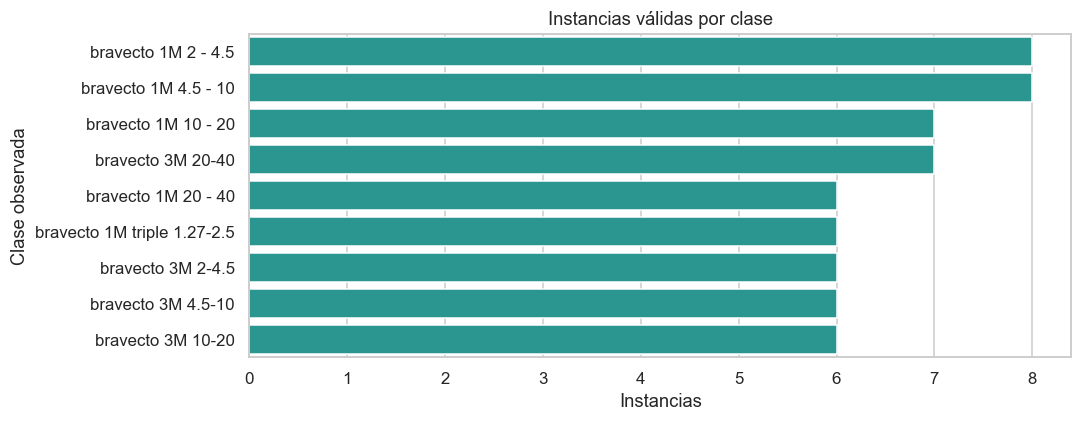

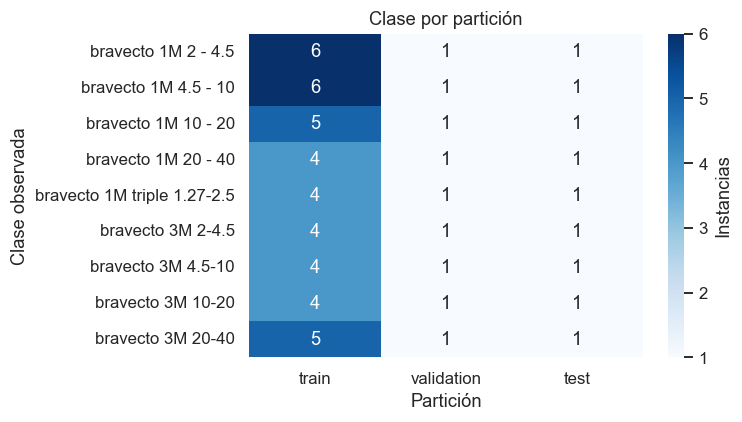

In [6]:
observed_ids = sorted(instances_df["class_id"].unique().tolist())
observed_names = [CLASS_NAMES[i] for i in observed_ids]
totals = (instances_df.groupby(["class_id", "clase"]).size()
          .rename("instancias").reset_index()
          .sort_values(["instancias", "class_id"], ascending=[False, True]))
split_counts = (instances_df.groupby(["clase", "split"]).size()
                .unstack(fill_value=0).reindex(index=observed_names, columns=list(SPLITS)).fillna(0).astype(int))
print(f"Cardinalidad observada: {len(observed_ids)} clases con instancias; mapa declarado: {len(CLASS_NAMES)}.")
display(split_counts)

fig, ax = plt.subplots(figsize=(10, max(4, 0.42 * len(totals))))
sns.barplot(data=totals, x="instancias", y="clase", color="#19a7a0", ax=ax)
ax.set(title="Instancias válidas por clase", xlabel="Instancias", ylabel="Clase observada")
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7, max(4, 0.42 * len(observed_names))))
sns.heatmap(split_counts, annot=True, fmt="g", cmap="Blues",
            cbar_kws={"label": "Instancias"}, ax=ax)
ax.set(title="Clase por partición", xlabel="Partición", ylabel="Clase observada")
plt.tight_layout(); plt.show()

## 6. Análisis univariante

Los histogramas describen variables continuas; las barras muestran el número de objetos por foto. El número de instancias por imagen permite comparar la muestra con las escenas de conteo previstas para el almacén.

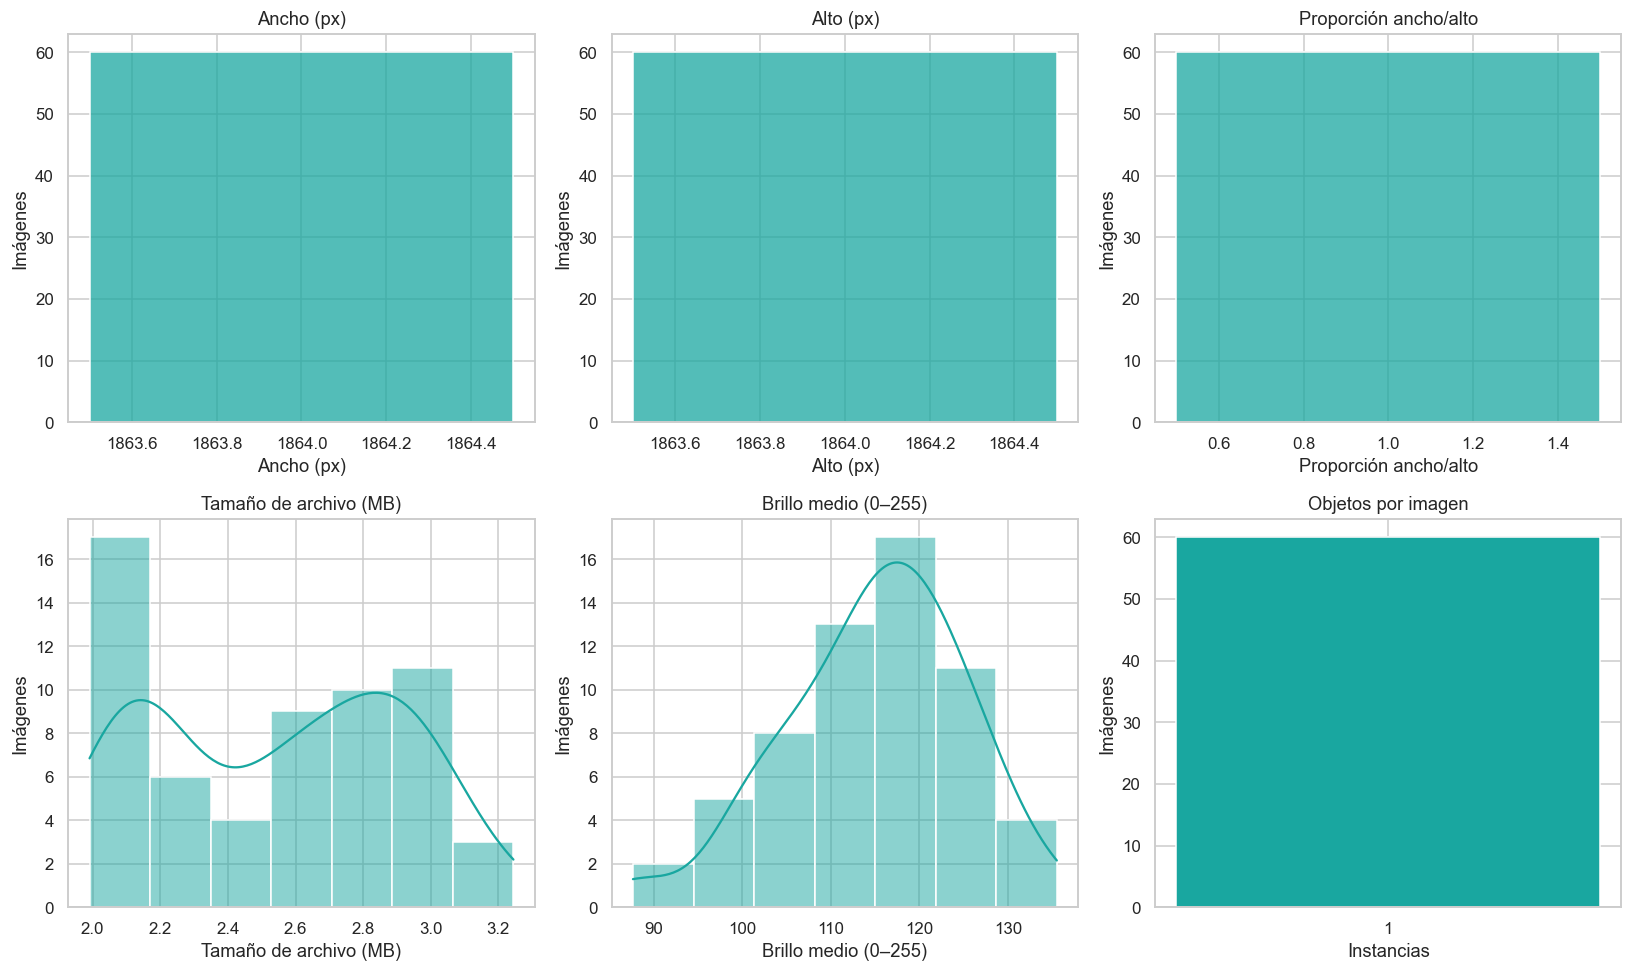

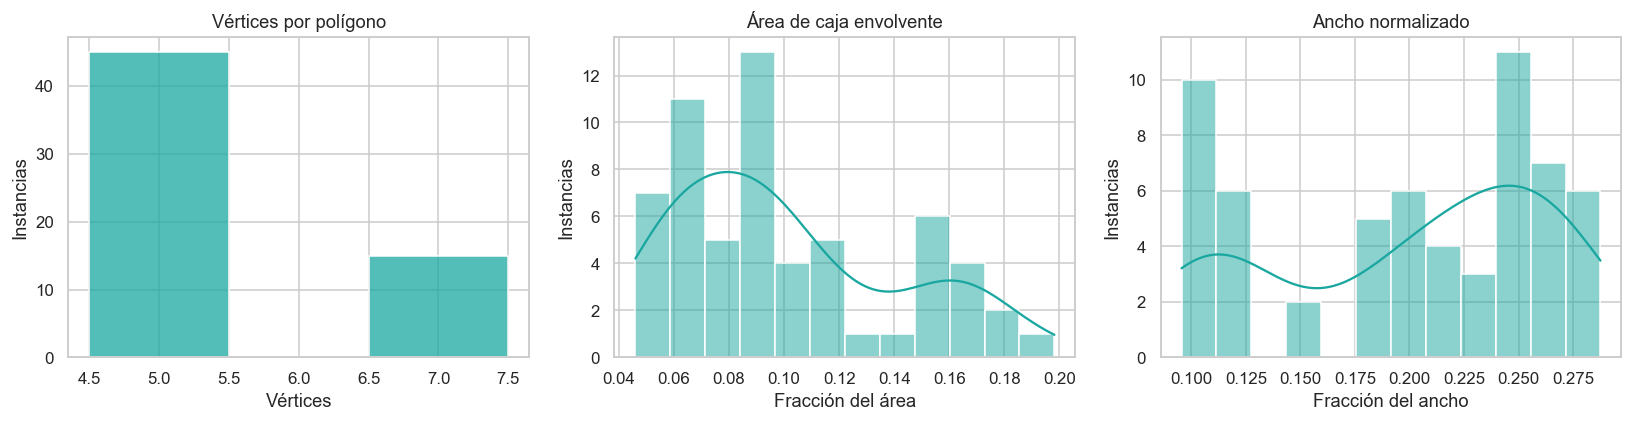

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
specs = [
    ("width", "Ancho (px)"), ("height", "Alto (px)"),
    ("aspect_ratio", "Proporción ancho/alto"),
    ("file_size_mb", "Tamaño de archivo (MB)"),
    ("brightness_mean", "Brillo medio (0–255)")
]
for ax, (col, label) in zip(axes.flat, specs):
    sns.histplot(data=images_df, x=col, bins="auto",
                 kde=images_df[col].nunique() > 5, color="#19a7a0", ax=ax)
    ax.set(title=label, xlabel=label, ylabel="Imágenes")
obj_counts = images_df["n_objects"].value_counts().sort_index()
axes.flat[5].bar(obj_counts.index.astype(str), obj_counts.values, color="#19a7a0")
axes.flat[5].set(title="Objetos por imagen", xlabel="Instancias", ylabel="Imágenes")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(data=instances_df, x="vertices", discrete=True, color="#19a7a0", ax=axes[0])
axes[0].set(title="Vértices por polígono", xlabel="Vértices", ylabel="Instancias")
sns.histplot(data=instances_df, x="bbox_area_fraction", bins=12, kde=True, color="#19a7a0", ax=axes[1])
axes[1].set(title="Área de caja envolvente", xlabel="Fracción del área", ylabel="Instancias")
sns.histplot(data=instances_df, x="bbox_width_norm", bins=12, kde=True, color="#19a7a0", ax=axes[2])
axes[2].set(title="Ancho normalizado", xlabel="Fracción del ancho", ylabel="Instancias")
plt.tight_layout(); plt.show()

### Distribución de intensidad de píxeles

Se toma una muestra reproducible de píxeles RGB de las imágenes etiquetadas para observar el rango de iluminación y color.

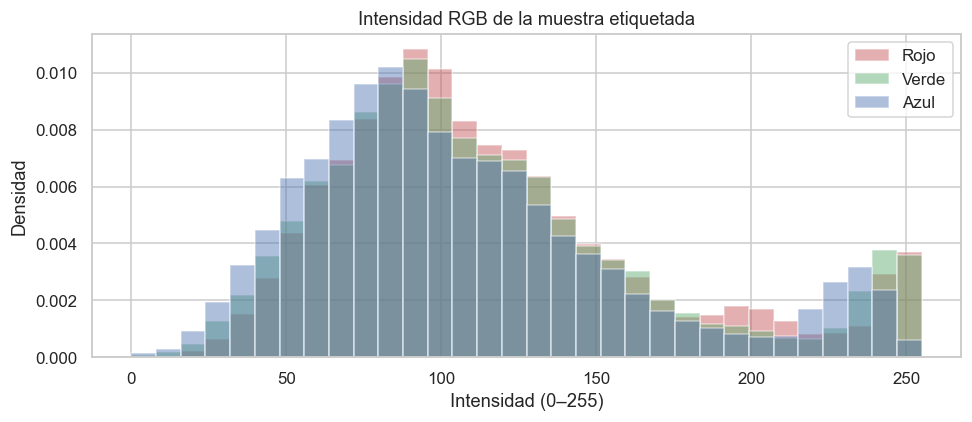

Rango RGB observado: 0 a 255


In [8]:
rng = np.random.default_rng(42)
pixel_samples = []
for path in images_df["image_path"]:
    arr = np.asarray(Image.open(path).convert("RGB"), dtype=np.uint8).reshape(-1, 3)
    take = min(2500, len(arr))
    pixel_samples.append(arr[rng.choice(len(arr), size=take, replace=False)])
sampled_rgb = np.concatenate(pixel_samples, axis=0)

fig, ax = plt.subplots(figsize=(9, 4))
for channel, color, label in [(0, "#c44e52", "Rojo"), (1, "#55a868", "Verde"), (2, "#4c72b0", "Azul")]:
    ax.hist(sampled_rgb[:, channel], bins=32, alpha=0.45, color=color, label=label, density=True)
ax.set(title="Intensidad RGB de la muestra etiquetada", xlabel="Intensidad (0–255)", ylabel="Densidad")
ax.legend(); plt.tight_layout(); plt.show()
print("Rango RGB observado:", int(sampled_rgb.min()), "a", int(sampled_rgb.max()))

## 7. Análisis bivariado y multivariado

La correlación de Spearman resume asociaciones monotónicas entre medidas de imagen y geometría. Se compara además el tamaño de objeto entre clases y se cuenta la coocurrencia. Los resultados son descriptivos; el tamaño de muestra no permite afirmar causalidad o generalización.

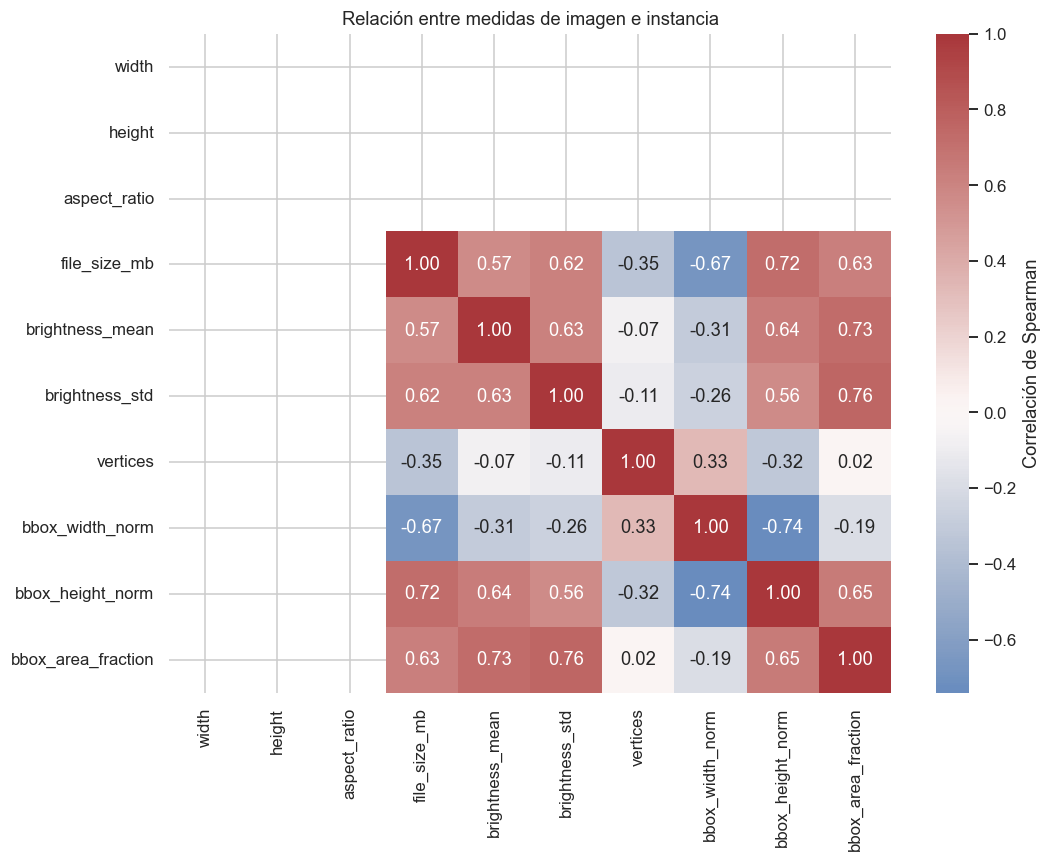

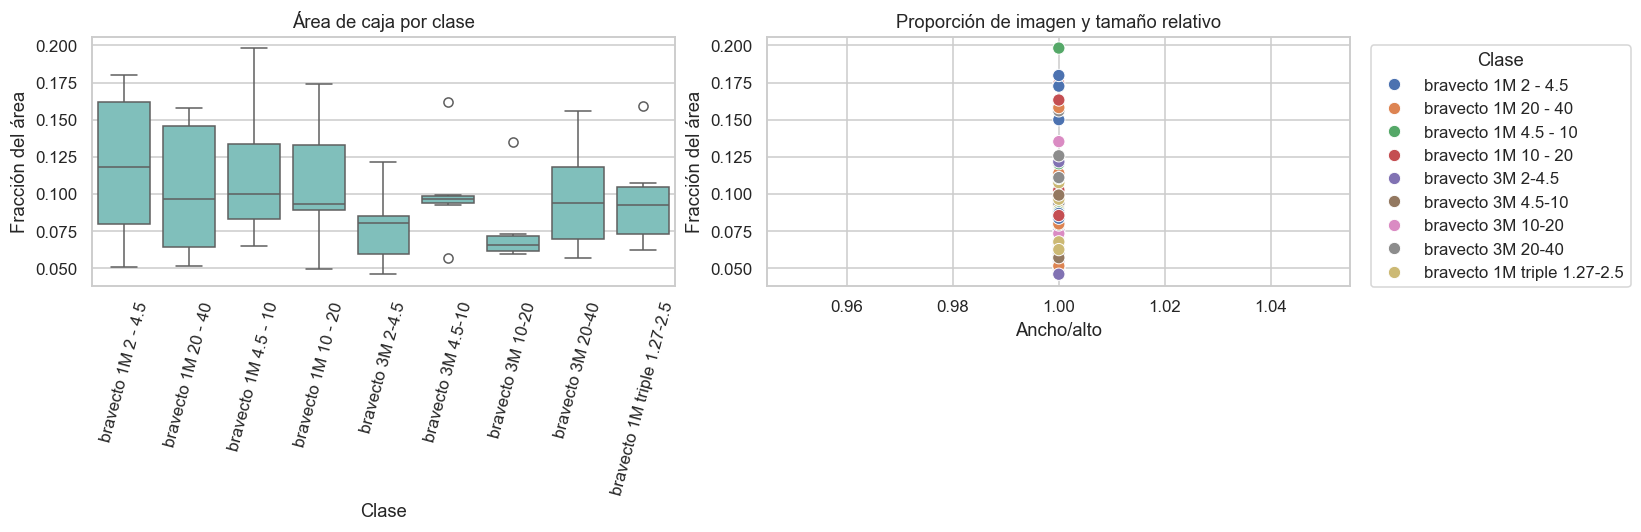

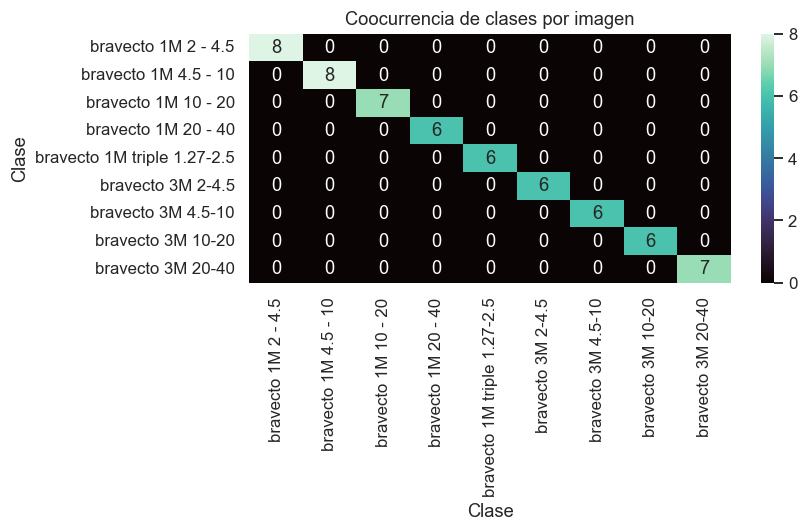

In [9]:
merged = instances_df.merge(
    images_df[["image_key", "width", "height", "aspect_ratio", "file_size_mb", "brightness_mean", "brightness_std"]],
    on="image_key", how="left"
)
features = ["width", "height", "aspect_ratio", "file_size_mb", "brightness_mean",
            "brightness_std", "vertices", "bbox_width_norm", "bbox_height_norm", "bbox_area_fraction"]
corr = merged[features].corr(method="spearman", numeric_only=True)
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="vlag", center=0, annot=True, fmt=".2f", ax=ax,
            cbar_kws={"label": "Correlación de Spearman"})
ax.set_title("Relación entre medidas de imagen e instancia")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=merged, x="clase", y="bbox_area_fraction", color="#75c9c4", ax=axes[0])
axes[0].set(title="Área de caja por clase", xlabel="Clase", ylabel="Fracción del área")
axes[0].tick_params(axis="x", rotation=75)
sns.scatterplot(data=merged, x="aspect_ratio", y="bbox_area_fraction", hue="clase", s=65, ax=axes[1])
axes[1].set(title="Proporción de imagen y tamaño relativo", xlabel="Ancho/alto", ylabel="Fracción del área")
axes[1].legend(title="Clase", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout(); plt.show()

cooc = pd.DataFrame(0, index=observed_names, columns=observed_names, dtype=int)
for _, group in instances_df.groupby("image_key"):
    present = sorted(set(group["clase"].tolist()))
    for a in present:
        for b in present:
            cooc.loc[a, b] += 1
fig, ax = plt.subplots(figsize=(8, max(5, 0.42 * len(observed_names))))
sns.heatmap(cooc, annot=True, fmt="g", cmap="mako", ax=ax)
ax.set(title="Coocurrencia de clases por imagen", xlabel="Clase", ylabel="Clase")
plt.tight_layout(); plt.show()

## 8. Inspección visual de la muestra

La revisión visual se realizó durante el análisis local. Esta copia pública no incrusta fotografías porque las cajas muestran datos comerciales de lote y caducidad. El resto del notebook conserva tablas y gráficas agregadas para documentar los hallazgos.

In [10]:
print("Inspección visual realizada localmente; se omiten las fotografías originales en la copia pública.")

Inspección visual realizada localmente; se omiten las fotografías originales en la copia pública.


## 9. Valores atípicos y preprocesamiento

Un valor extremo de proporción, brillo o tamaño de objeto puede ser una foto diferente, un producto parcialmente visible o un error. Se marca con IQR para inspección visual, sin eliminación automática. Las coordenadas del polígono ya están normalizadas.

In [11]:
def resumen_iqr(serie):
    s = pd.to_numeric(serie, errors="coerce").dropna()
    if len(s) < 4:
        return {"n": len(s), "limite_inferior": np.nan, "limite_superior": np.nan, "candidatos": 0}
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    return {"n": len(s), "limite_inferior": low, "limite_superior": high,
            "candidatos": int(((s < low) | (s > high)).sum())}

variables_outlier = {
    "ancho_px": images_df["width"], "alto_px": images_df["height"],
    "proporción": images_df["aspect_ratio"], "brillo_medio": images_df["brightness_mean"],
    "área_caja": instances_df["bbox_area_fraction"],
    "ancho_caja": instances_df["bbox_width_norm"],
}
outliers = pd.DataFrame({name: resumen_iqr(series) for name, series in variables_outlier.items()}).T
outliers.index.name = "variable"
display(outliers.round(4))

def normalizar_rgb(ruta):
    pixeles = np.asarray(Image.open(ruta).convert("RGB"), dtype=np.uint8)
    return pixeles.astype(np.float32) / 255.0

ejemplo = normalizar_rgb(images_df.iloc[0]["image_path"])
print("Entrada RGB:", ejemplo.shape, ejemplo.dtype,
      "rango observado:", (float(ejemplo.min()), float(ejemplo.max())))

,n,limite_inferior,limite_superior,candidatos
variable,,,,
ancho_px,60.0,1864.0000,1864.0000,0.0
alto_px,60.0,1864.0000,1864.0000,0.0
proporción,60.0,1.0000,1.0000,0.0
brillo_medio,60.0,87.6514,142.4829,0.0
área_caja,60.0,-0.0152,0.2054,0.0
ancho_caja,60.0,-0.0628,0.4394,0.0


Entrada RGB: (1864, 1864, 3) float32 rango observado: (0.0, 1.0)


### Decisiones justificadas

| Hallazgo | Tratamiento aplicado o recomendado | Motivo |
|---|---|---|
| Imagen sin etiqueta, etiqueta vacía o sin polígono válido | Excluir de esta muestra y reportar el motivo | El objetivo es analizar solo los datos etiquetados; no se inventan máscaras |
| Polígono inválido | Validar clase, coordenadas y rango; no incluirlo en métricas | Evita contaminar el análisis sin alterar la fuente |
| Candidato atípico IQR | Inspeccionar sobre la imagen; conservar si es un caso real | El tamaño o encuadre puede representar variación del negocio |
| Clases declaradas | Mantener IDs y contar las que aparecen en la muestra | Las presentaciones son categorías distintas; renumerar rompe el mapa |
| Píxeles RGB | Escalar de uint8 [0,255] a float32 [0,1] para el modelo | Preprocesamiento reproducible y reversible |
| Brillo y fondo | No aplicar ecualización global sin comprobar el efecto en empaques | Una transformación agresiva puede quitar señales de color o texto |
| Particiones | Considerar la advertencia del manifiesto sobre división temporal | Para una evaluación futura, conviene separar por sesión de captura |

El análisis no modifica archivos fuente. Una corrección definitiva debe guardarse en una nueva versión del dataset con su manifiesto.

## 10. Conclusiones del EDA

La siguiente celda resume la muestra etiquetada válida. Completa después las observaciones del equipo a partir de los histogramas y la inspección visual.

In [12]:
present_ids = set(instances_df["class_id"].unique().tolist())
absent_declared = [CLASS_NAMES[i] for i in range(len(CLASS_NAMES)) if i not in present_ids]
print("CONCLUSIONES — MUESTRA ETIQUETADA")
print(f"- Muestra completa disponible analizada: {len(images_df)} imágenes y {len(instances_df)} instancias.")
print(f"- Cardinalidad observada: {len(present_ids)} clases con ejemplos de {len(CLASS_NAMES)} IDs declarados.")
print("- Frecuencia por clase:")
for _, row in totals.sort_values("class_id").iterrows():
    print(f"  · {row['clase']}: {int(row['instancias'])}")
print(f"- Imágenes excluidas: {len(excluded_df)}; anotaciones inválidas detectadas: {len(invalid_df)}.")
print("- Objetos por imagen:", images_df["n_objects"].value_counts().sort_index().to_dict())
print("- Candidatos atípicos IQR:")
for name, row in outliers.iterrows():
    print(f"  · {name}: {int(row['candidatos'])}")
if absent_declared:
    print("- Clases declaradas sin instancias en esta muestra:", "; ".join(absent_declared))
print("- Las frecuencias por partición son descriptivas; la muestra no basta para estimar de forma estable precisión, recall o error de conteo.")
print("- El manifiesto advierte que la partición es temporal determinista; no demuestra independencia entre sesiones.")

CONCLUSIONES — MUESTRA ETIQUETADA
- Muestra completa disponible analizada: 60 imágenes y 60 instancias.
- Cardinalidad observada: 9 clases con ejemplos de 20 IDs declarados.
- Frecuencia por clase:
  · bravecto 1M 2 - 4.5: 8
  · bravecto 1M 4.5 - 10: 8
  · bravecto 1M 10 - 20: 7
  · bravecto 1M 20 - 40: 6
  · bravecto 1M triple 1.27-2.5: 6
  · bravecto 3M 2-4.5: 6
  · bravecto 3M 4.5-10: 6
  · bravecto 3M 10-20: 6
  · bravecto 3M 20-40: 7
- Imágenes excluidas: 0; anotaciones inválidas detectadas: 0.
- Objetos por imagen: {1: 60}
- Candidatos atípicos IQR:
  · ancho_px: 0
  · alto_px: 0
  · proporción: 0
  · brillo_medio: 0
  · área_caja: 0
  · ancho_caja: 0
- Clases declaradas sin instancias en esta muestra: bravecto 1M triple 2.5-5.0; bravecto 1M triple 5.0-10; bravecto 1M triple 10-20; bravecto 1M triple 20-40; bravecto 1M triple 40-60; bravecto 2-4.5; bravecto 3M 40-56; bravecto 365; bravecto pipeta 4.5-10; bravecto pipeta 10-20; bravecto pipeta 20-40
- Las frecuencias por partición

## Conclusiones del EDA

- El dataset y sus anotaciones se procesaron correctamente a nivel de formato: 60 imágenes y 60 instancias válidas, sin imágenes excluidas ni líneas YOLO inválidas. La revisión visual sí encontró algunas máscaras posiblemente parciales o desplazadas; conviene verificarlas antes de entrenar.
- Se identificaron 9 clases presentes de las 20 definidas.
- No se observa un desbalance importante entre las 9 clases presentes: sus frecuencias van de 6 a 8 instancias. Las otras 11 clases no están representadas en esta muestra.
- Existen variaciones en iluminación y en el tamaño y proporción de los objetos. Las imágenes tienen la misma resolución, 1864 × 1864 px.
- El conjunto actual es suficiente para continuar con la siguiente etapa de análisis y preparación; no basta por sí solo para validar el modelo final.

## Conclusiones del equipo

El conjunto actual funciona como punto de partida, pero todavía necesita mayor cobertura de clases y más diversidad de imágenes antes de entrenar el modelo final. Las variaciones observadas en iluminación y tamaño no se consideran necesariamente errores, ya que pueden representar condiciones reales de uso del sistema. Las máscaras dudosas deben confirmarse con una revisión visual del etiquetado.

## Next steps

- Ampliar el conjunto de datos para cubrir las clases que aún no aparecen.
- Incorporar más imágenes con variaciones de iluminación, posición y tamaño de los productos.
- Revisar visualmente los casos atípicos y las máscaras parcialmente desalineadas antes de decidir si deben excluirse o corregirse.
- Mantener un preprocesamiento consistente de imágenes y anotaciones.
- Revisar y documentar la división existente de train, validation y test; el manifiesto advierte que la partición actual es temporal determinista.
- Continuar con la etapa de entrenamiento y evaluación del modelo de segmentación cuando la calidad de las máscaras sea confirmada.